In [ ]:
import pandas as pd
import numpy as np
# Load both files
clients = pd.read_csv("/content/clients.csv")
props = pd.read_csv("/content/properties.csv")

In [ ]:
#Keep only sold units (only these have a buyer)
sold = props[props["listing_status"] == "Sold"].copy()

#Fix data types: price text "$300,385.62" -> number, date text -> date
sold["sale_price"] = sold["sale_price"].str.replace(r"[$,]", "", regex=True).astype(float)
sold["transaction_date"] = pd.to_datetime(sold["transaction_date"], format="%m-%d-%Y")
sold["is_office"] = (sold["unit_category"] == "Office").astype(int)

In [ ]:
#Summarise purchases per buyer (one row per client)
buyer_stats = sold.groupby("client_ref").agg(
    units_bought=("listing_id", "count"),
    total_spend=("sale_price", "sum"),
    avg_price=("sale_price", "mean"),
    avg_area_sqft=("floor_area_sqft", "mean"),
    office_share=("is_office", "mean"),
).reset_index().rename(columns={"client_ref": "client_id"})
print(buyer_stats.shape)
buyer_stats.head()

(2000, 6)


,client_id,units_bought,total_spend,avg_price,avg_area_sqft,office_share
0,C0001,4,1246764.72,311691.180000,983.885000,0.0
1,C0002,5,1841095.93,368219.186000,1187.942000,0.0
2,C0003,5,1661457.59,332291.518000,1058.110000,0.0
3,C0004,6,1608263.51,268043.918333,937.103333,0.0
4,C0005,13,3653385.38,281029.644615,927.296154,0.0


In [ ]:
# Merge buyer stats into the client table
df = clients.merge(buyer_stats, on="client_id", how="left")

In [ ]:
# Clean: duplicates, text labels, missing values
df = df.drop_duplicates(subset="client_id")
for col in ["client_type", "gender", "country", "region",
            "acquisition_purpose", "loan_applied", "referral_channel"]:
    df[col] = df[col].str.strip().str.title()
df[["units_bought", "total_spend", "avg_price", "avg_area_sqft", "office_share"]] = \
    df[["units_bought", "total_spend", "avg_price", "avg_area_sqft", "office_share"]].fillna(0)

In [ ]:
# Age from date of birth (fixed reference date so results never change)
df["date_of_birth"] = pd.to_datetime(df["date_of_birth"], format="mixed")
df["age"] = ((pd.Timestamp("2026-01-01") - df["date_of_birth"]).dt.days / 365.25).round(0).astype(int)

# Drop personal names (not useful for clustering)
df = df.drop(columns=["first_name", "last_name", "date_of_birth"])

In [ ]:
#Quick check
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print(df[["age", "satisfaction_score", "units_bought", "total_spend"]].describe().round(1))

(2000, 15)
Missing values: 0
          age  satisfaction_score  units_bought  total_spend
count  2000.0              2000.0        2000.0       2000.0
mean     55.6                 3.0           3.7    1260375.5
std      17.4                 1.4           0.8     347830.7
min      25.0                 1.0           3.0     463612.0
25%      41.0                 2.0           3.0    1025238.0
50%      56.0                 3.0           4.0    1220893.2
75%      70.0                 4.0           4.0    1441973.9
max      95.0                 5.0          13.0    3653385.4


In [ ]:
df["country"] = df["country"].replace({"Usa": "USA", "Uk": "UK"})

In [ ]:
# Yes/No columns -> 0/1
enc = pd.DataFrame(index=df.index)
enc["client_type_company"] = (df["client_type"] == "Company").astype(int)
enc["purpose_investment"] = (df["acquisition_purpose"] == "Investment").astype(int)
enc["loan_yes"] = (df["loan_applied"] == "Yes").astype(int)

# Country -> international buyer flag (1 = outside USA)
enc["is_international"] = (df["country"] != "USA").astype(int)

# Referral channel -> one-hot columns
referral = pd.get_dummies(df["referral_channel"], prefix="ref", dtype=int)

In [ ]:
from sklearn.preprocessing import StandardScaler
# Numeric features (log on skewed columns)
num = df[["age", "satisfaction_score", "units_bought", "total_spend", "office_share"]].copy()
num["units_bought"] = np.log1p(num["units_bought"])
num["total_spend"] = np.log1p(num["total_spend"])

# Combine all features into one table
X = pd.concat([num, enc, referral], axis=1)

# Scale everything to the same range
X_scaled = StandardScaler().fit_transform(X)

In [ ]:
#Quick check
print(X.shape)
print(list(X.columns))
print(pd.DataFrame(X_scaled, columns=X.columns).describe().loc[["mean", "std"]].round(2))

(2000, 12)
['age', 'satisfaction_score', 'units_bought', 'total_spend', 'office_share', 'client_type_company', 'purpose_investment', 'loan_yes', 'is_international', 'ref_Agency', 'ref_Client', 'ref_Website']
      age  satisfaction_score  units_bought  total_spend  office_share  \
mean -0.0                 0.0          -0.0          0.0           0.0   
std   1.0                 1.0           1.0          1.0           1.0   

      client_type_company  purpose_investment  loan_yes  is_international  \
mean                  0.0                -0.0       0.0               0.0   
std                   1.0                 1.0       1.0               1.0   

      ref_Agency  ref_Client  ref_Website  
mean        -0.0        -0.0          0.0  
std          1.0         1.0          1.0  


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    gm = GaussianMixture(n_components=k, random_state=42).fit_predict(X_scaled)
    rows.append([k, km.inertia_,
                 silhouette_score(X_scaled, km.labels_),
                 silhouette_score(X_scaled, hc),
                 silhouette_score(X_scaled, gm)])

scores = pd.DataFrame(rows, columns=["k", "inertia", "KMeans", "Hier", "GMM"])
print(scores.round(3))

   k    inertia  KMeans   Hier    GMM
0  2  20391.021   0.170  0.160  0.170
1  3  17989.923   0.205  0.181  0.205
2  4  16799.249   0.152  0.213  0.211
3  5  15181.888   0.165  0.183  0.150
4  6  14264.808   0.192  0.193  0.169
5  7  13612.389   0.182  0.177  0.155
6  8  12967.433   0.158  0.186  0.134


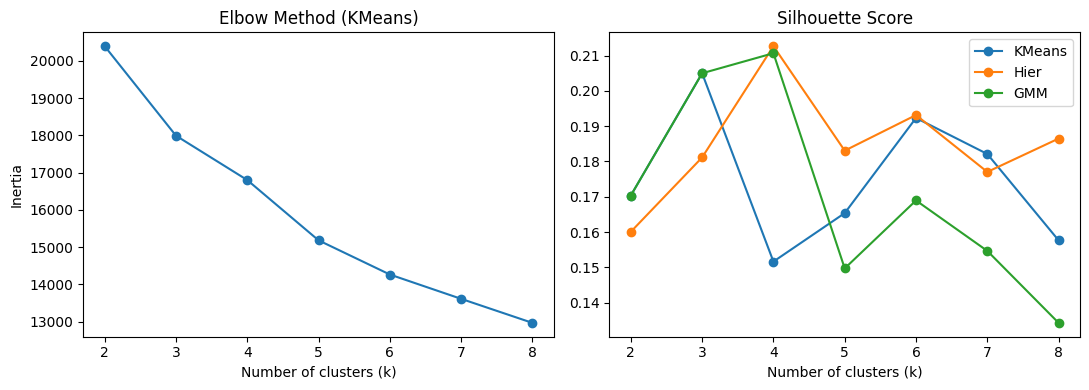

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Elbow plot
ax[0].plot(scores["k"], scores["inertia"], marker="o")
ax[0].set_title("Elbow Method (KMeans)")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia")

# Silhouette plot
for m in ["KMeans", "Hier", "GMM"]:
    ax[1].plot(scores["k"], scores[m], marker="o", label=m)
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# --- Final features: drop referral columns and units_bought (kept in df for Power BI) ---
X_final = X.drop(columns=list(referral.columns) + ["units_bought"])
X_final_scaled = StandardScaler().fit_transform(X_final)
print("Features used:", list(X_final.columns))

Features used: ['age', 'satisfaction_score', 'total_spend', 'office_share', 'client_type_company', 'purpose_investment', 'loan_yes', 'is_international']


In [ ]:
# Re-check the number of clusters on the FINAL features
rows = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_final_scaled)
    hc_k = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_final_scaled)
    rows.append([k, km_k.inertia_,
                 silhouette_score(X_final_scaled, km_k.labels_),
                 silhouette_score(X_final_scaled, hc_k)])
print(pd.DataFrame(rows, columns=["k", "inertia", "KMeans", "Hierarchical"]).round(3))

   k    inertia  KMeans  Hierarchical
0  2  13975.087   0.381         0.381
1  3  12079.029   0.185         0.206
2  4  10607.646   0.196         0.193
3  5   9814.445   0.162         0.183
4  6   9039.791   0.167         0.152
5  7   8578.054   0.185         0.170
6  8   8200.909   0.191         0.189


In [ ]:
# Final model: Hierarchical (Ward), k = 4
df["cluster"] = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_final_scaled)

#  0/1 flags (also useful in Power BI)
df["is_investment"] = (df["acquisition_purpose"] == "Investment").astype(int)
df["is_loan"] = (df["loan_applied"] == "Yes").astype(int)
df["is_company"] = (df["client_type"] == "Company").astype(int)
df["is_international"] = (df["country"] != "USA").astype(int)

In [ ]:
# Cluster summary: size, share and average values
prof = df.groupby("cluster").agg(
    customers=("client_id", "count"),
    avg_age=("age", "mean"),
    avg_satisfaction=("satisfaction_score", "mean"),
    avg_units_bought=("units_bought", "mean"),
    avg_total_spend=("total_spend", "mean"),
    investment_pct=("is_investment", "mean"),
    loan_pct=("is_loan", "mean"),
    company_pct=("is_company", "mean"),
    international_pct=("is_international", "mean"),
)
prof["share_pct"] = prof["customers"] / prof["customers"].sum() * 100

In [ ]:
# Name each cluster from its own data
names = {}
names[prof["company_pct"].idxmax()] = "Corporate Buyers"
names[prof["international_pct"].drop(index=list(names)).idxmax()] = "International Buyers"
rest = prof.drop(index=list(names))
names[rest["investment_pct"].idxmax()] = "Domestic Investors"
names[rest["investment_pct"].idxmin()] = "Domestic Home Buyers"

actions = {
    "Corporate Buyers": "Offer bulk-unit packages, financing tie-ups and a dedicated account manager.",
    "International Buyers": "Run remote-buying support and country-focused marketing (UK, Canada, Germany first).",
    "Domestic Investors": "Promote rental-yield and resale-value units with investor-focused offers.",
    "Domestic Home Buyers": "Promote family-friendly units, loan support and after-sales service.",
}

In [ ]:
df["cluster_name"] = df["cluster"].map(names)
df["business_action"] = df["cluster_name"].map(actions)
prof["cluster_name"] = prof.index.map(names)
prof["business_action"] = prof["cluster_name"].map(actions)
summary = prof.reset_index().round(2)

print(summary[["cluster", "cluster_name", "customers", "share_pct", "avg_age",
               "avg_satisfaction", "avg_units_bought", "avg_total_spend",
               "investment_pct", "loan_pct", "company_pct", "international_pct"]])

   cluster          cluster_name  customers  share_pct  avg_age  \
0        0  Domestic Home Buyers       1023      51.15    56.91   
1        1    Domestic Investors        435      21.75    55.41   
2        2  International Buyers        439      21.95    54.59   
3        3      Corporate Buyers        103       5.15    47.66   

   avg_satisfaction  avg_units_bought  avg_total_spend  investment_pct  \
0              3.04              3.70       1281644.63            0.01   
1              3.00              3.62       1238427.43            1.00   
2              3.03              3.57       1231767.56            0.31   
3              3.07              3.70       1263753.49            0.35   

   loan_pct  company_pct  international_pct  
0      0.36          0.0               0.00  
1      0.37          0.0               0.00  
2      0.36          0.0               1.00  
3      0.42          1.0               0.22  


In [ ]:
# Save the two files
df.to_csv("buyer_segments1.csv", index=False)
summary.to_csv("cluster_summary1.csv", index=False)

# Download them
from google.colab import files
files.download("buyer_segments1.csv")
files.download("cluster_summary1.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>